Dataset Loaded Successfully. Shape: (10, 3)

Preprocessing text using SpaCy (lemmatization & stopword removal)...
Note: Skipping stratification because at least one class has fewer than 2 members.

Training classifiers...

           MODEL PERFORMANCE BENCHMARK            
Multinomial Naive Bayes Accuracy : 0.3333
Logistic Regression Accuracy     : 0.3333

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
    positive       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3



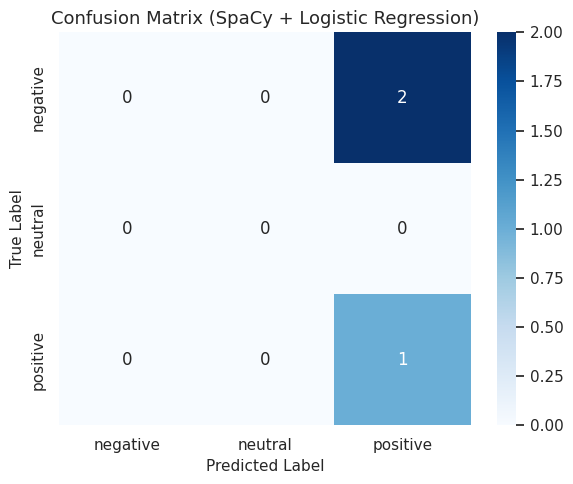

--- Testing Live SpaCy Preprocessed Predictions ---
Input Text : "Exceeded my expectations, absolutely wonderful quality and easy to use!"
  -> Naive Bayes       : POSITIVE (Confidence: 91.47%)
  -> Logistic Reg      : POSITIVE (Confidence: 47.51%)

Input Text : "Horrible experience, broke instantly and terrible customer support."
  -> Naive Bayes       : POSITIVE (Confidence: 57.14%)
  -> Logistic Reg      : POSITIVE (Confidence: 40.45%)

Input Text : "It is average, decent for the price point."
  -> Naive Bayes       : NEUTRAL (Confidence: 93.95%)
  -> Logistic Reg      : NEUTRAL (Confidence: 48.10%)



In [5]:
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import spacy

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Load SpaCy English language model (disabling parser and NER for speed)
try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
except OSError:
    import os
    print("Downloading spaCy model 'en_core_web_sm'...")
    os.system("python -m spacy download en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

# Set visual style
sns.set_theme(style="whitegrid")

def run_spacy_sentiment_pipeline():
    # 1. Load Dataset from CSV string
    csv_data = """review_id,review_text,sentiment
1,"The product quality is exceptional, exceeded all my expectations!",positive
2,"Terrible customer service and the item arrived completely damaged.",negative
3,"Average performance, decent for the price point but nothing special.",neutral
4,"Absolutely love this! Easy to setup, robust, and works flawlessly.",positive
5,"Stopped working after two days. Extremely disappointed with the purchase.",negative
6,"Customer support helped resolve my setup question within ten minutes.",positive
7,"Delivery was slow and package was missing one adapter cable.",negative
8,"Clean interface and intuitive controls. Highly recommended for students.",positive
9,"Not worth the money, plenty of better alternatives available.",negative
10,"Great value and durable build. Would definitely purchase again.",positive"""

    df = pd.read_csv(io.StringIO(csv_data))
    print(f"Dataset Loaded Successfully. Shape: {df.shape}\n")

    # 2. Advanced SpaCy Text Preprocessing & Lemmatization
    print("Preprocessing text using SpaCy (lemmatization & stopword removal)...")
    def clean_text_spacy(text):
        doc = nlp(str(text))
        # Filter out stopwords, punctuation, non-alphabetic tokens, and extract lemmas
        tokens = [
            token.lemma_.lower()
            for token in doc
            if not token.is_stop and not token.is_punct and token.is_alpha
        ]
        return " ".join(tokens)

    df['cleaned_text'] = df['review_text'].apply(clean_text_spacy)

    X = df['cleaned_text']
    y = df['sentiment']

    # 3. Train/Test Split (Safe check for small dataset sizes)
    class_counts = y.value_counts()
    if len(df) > 5 and class_counts.min() >= 2:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.30, random_state=42, stratify=y
        )
    else:
        print("Note: Skipping stratification because at least one class has fewer than 2 members.\n")
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.30, random_state=42
        )

    # 4. TF-IDF Feature Extraction with n-grams
    vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 3), sublinear_tf=True)
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    # 5. Train Models (Multinomial Naive Bayes & Logistic Regression)
    print("Training classifiers...")
    nb_classifier = MultinomialNB(alpha=0.1)
    nb_classifier.fit(X_train_tfidf, y_train)

    lr_classifier = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    lr_classifier.fit(X_train_tfidf, y_train)

    # 6. Evaluation & Benchmarking
    y_pred_nb = nb_classifier.predict(X_test_tfidf)
    y_pred_lr = lr_classifier.predict(X_test_tfidf)

    acc_nb = accuracy_score(y_test, y_pred_nb)
    acc_lr = accuracy_score(y_test, y_pred_lr)

    print("\n==================================================")
    print("           MODEL PERFORMANCE BENCHMARK            ")
    print("==================================================")
    print(f"Multinomial Naive Bayes Accuracy : {acc_nb:.4f}")
    print(f"Logistic Regression Accuracy     : {acc_lr:.4f}")
    print("==================================================\n")

    print("--- Logistic Regression Classification Report ---")
    print(classification_report(y_test, y_pred_lr, zero_division=0))

    # 7. Visual Confusion Matrix
    plt.figure(figsize=(6, 5))
    cm = confusion_matrix(y_test, y_pred_lr, labels=lr_classifier.classes_)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=lr_classifier.classes_,
                yticklabels=lr_classifier.classes_)
    plt.title("Confusion Matrix (SpaCy + Logistic Regression)", fontsize=13)
    plt.xlabel("Predicted Label", fontsize=11)
    plt.ylabel("True Label", fontsize=11)
    plt.tight_layout()
    plt.show()

    # 8. Live Prediction Function
    def predict_sentiment(input_text):
        cleaned = clean_text_spacy(input_text)
        vectorized = vectorizer.transform([cleaned])

        # Naive Bayes prediction
        nb_pred = nb_classifier.predict(vectorized)[0]
        nb_prob = nb_classifier.predict_proba(vectorized)[0]
        nb_conf = nb_prob[list(nb_classifier.classes_).index(nb_pred)] * 100

        # Logistic Regression prediction
        lr_pred = lr_classifier.predict(vectorized)[0]
        lr_prob = lr_classifier.predict_proba(vectorized)[0]
        lr_conf = lr_prob[list(lr_classifier.classes_).index(lr_pred)] * 100

        print(f"Input Text : \"{input_text}\"")
        print(f"  -> Naive Bayes       : {nb_pred.upper()} (Confidence: {nb_conf:.2f}%)")
        print(f"  -> Logistic Reg      : {lr_pred.upper()} (Confidence: {lr_conf:.2f}%)\n")

    print("--- Testing Live SpaCy Preprocessed Predictions ---")
    predict_sentiment("Exceeded my expectations, absolutely wonderful quality and easy to use!")
    predict_sentiment("Horrible experience, broke instantly and terrible customer support.")
    predict_sentiment("It is average, decent for the price point.")

if __name__ == "__main__":
    run_spacy_sentiment_pipeline()